# 🚢 Clustering Analysis - AIS Vessel Data
Ce notebook effectue une analyse de clustering sur les données de positions des navires AIS.

**Objectifs:**
- Connexion à la base de données PostgreSQL distante
- Extraction et préparation des données
- Clustering des navires par comportement et position
- Visualisation des résultats

## 📦 1. Import des bibliothèques

In [4]:
# Installer les dépendances nécessaires
%pip install --quiet psycopg2-binary

Note: you may need to restart the kernel to use updated packages.


In [5]:
import psycopg2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

## 🔌 2. Connexion à la base de données PostgreSQL

In [6]:
# Paramètres de connexion
DB_CONFIG = {
    'host': '172.31.60.8',
    'port': 5432,
    'database': 'ais',
    'user': 'postgres',
    'password': 'ANjw/84H77C9h2'
}

# Connexion
try:
    conn = psycopg2.connect(**DB_CONFIG)
    print("✅ Connexion réussie à la base de données PostgreSQL!")
    
    # Vérification
    cursor = conn.cursor()
    cursor.execute("SELECT version();")
    version = cursor.fetchone()
    print(f"📊 Version PostgreSQL: {version[0][:50]}...")
    cursor.close()
    
except Exception as e:
    print(f"❌ Erreur de connexion: {e}")

✅ Connexion réussie à la base de données PostgreSQL!
📊 Version PostgreSQL: PostgreSQL 16.9 (Debian 16.9-1.pgdg110+1) on x86_6...


## 📊 3. Exploration des données

In [7]:
# Compter le nombre de navires et positions
query_stats = """
SELECT 
    (SELECT COUNT(*) FROM vessel) as total_vessels,
    (SELECT COUNT(*) FROM position_vessel) as total_positions,
    (SELECT COUNT(DISTINCT vessel_type_id) FROM vessel WHERE vessel_type_id IS NOT NULL) as vessel_types
"""

df_stats = pd.read_sql(query_stats, conn)
print("\n📈 Statistiques de la base de données:")
print(f"   Nombre de navires: {df_stats['total_vessels'][0]:,}")
print(f"   Nombre de positions: {df_stats['total_positions'][0]:,}")
print(f"   Types de navires différents: {df_stats['vessel_types'][0]}")


📈 Statistiques de la base de données:
   Nombre de navires: 81,593
   Nombre de positions: 19,242,812
   Types de navires différents: 87


## 🎯 4. Extraction des données pour le clustering
On va extraire les données de navigation avec les positions géographiques

In [8]:
# Requête pour extraire les données agrégées par navire
query_clustering = """
WITH vessel_positions AS (
    SELECT
        pv.vessel_id,
        pv.sog,
        pv.cog,
        pv.heading,
        pv.status_id,
        pv.base_date_time,
        ST_X(pv.geom::geometry) AS longitude,
        ST_Y(pv.geom::geometry) AS latitude,
        ST_Distance(
            pv.geom::geography,
            LAG(pv.geom::geography) OVER (PARTITION BY pv.vessel_id ORDER BY pv.base_date_time)
        ) AS step_distance
    FROM position_vessel pv
),
aggregated AS (
    SELECT
        v.id AS vessel_id,
        v.mmsi,
        v.vessel_name,
        v.vessel_type_id,
        vt.description AS vessel_type,
        v.length,
        v.width,
        v.draft,
        COUNT(vp.base_date_time) AS position_count,
        AVG(vp.sog) AS avg_speed,
        STDDEV(vp.sog) AS std_speed,
        AVG(vp.cog) AS avg_course,
        AVG(vp.heading) AS avg_heading,
        AVG(vp.longitude) AS avg_longitude,
        AVG(vp.latitude) AS avg_latitude,
        STDDEV(vp.longitude) AS std_longitude,
        STDDEV(vp.latitude) AS std_latitude,
        SUM(COALESCE(vp.step_distance, 0)) / 1000.0 AS total_distance_km,
        MODE() WITHIN GROUP (ORDER BY vp.status_id) AS most_common_status
    FROM vessel v
    JOIN vessel_positions vp ON vp.vessel_id = v.id
    LEFT JOIN vessel_type vt ON v.vessel_type_id = vt.id
    GROUP BY v.id, v.mmsi, v.vessel_name, v.vessel_type_id, vt.description, v.length, v.width, v.draft
    HAVING COUNT(vp.base_date_time) >= 10
)
SELECT *
FROM aggregated
ORDER BY vessel_id;
"""

print("Extraction de TOUTES les données (cela peut prendre plusieurs minutes)...")
df = pd.read_sql(query_clustering, conn)
print(f"{len(df)} navires extraits avec leurs caractéristiques")
print(f"\nColonnes disponibles: {df.columns.tolist()}")
df.head()

Extraction de TOUTES les données (cela peut prendre plusieurs minutes)...
61010 navires extraits avec leurs caractéristiques

Colonnes disponibles: ['vessel_id', 'mmsi', 'vessel_name', 'vessel_type_id', 'vessel_type', 'length', 'width', 'draft', 'position_count', 'avg_speed', 'std_speed', 'avg_course', 'avg_heading', 'avg_longitude', 'avg_latitude', 'std_longitude', 'std_latitude', 'total_distance_km', 'most_common_status']


,vessel_id,mmsi,vessel_name,vessel_type_id,vessel_type,length,width,draft,position_count,avg_speed,std_speed,avg_course,avg_heading,avg_longitude,avg_latitude,std_longitude,std_latitude,total_distance_km,most_common_status
0,24084,109050650,109050650,NaN,None,100.0,NaN,NaN,19,4.568421,6.461429,178.526316,NaN,-94.940900,29.478935,0.007399,0.004616,1.188051e+01,NaN
1,24086,112119600,TRIPLET PRODUCTION,30.0,Fishing,NaN,NaN,NaN,974,3.897639,2.148750,179.464374,NaN,-91.926327,29.218630,0.526379,0.278671,4.980116e+03,NaN
2,24087,119000991,ONWASHENZHEN,57.0,Spare - for assignment to local vessel,29.0,17.0,NaN,24,0.841667,1.373006,207.062500,206.625000,-79.214698,43.703118,0.024867,0.016079,3.316430e+01,NaN
3,24088,123456789,ODYSSEY,37.0,Pleasure Craft,25.0,10.0,6.0,2998,5.517045,8.814599,141.277856,163.603175,-81.148186,28.300561,6.301189,4.175400,1.253453e+06,0.0
4,24089,155017179,0.C.D,37.0,Pleasure Craft,16.0,4.0,NaN,171,2.966082,6.406735,159.482456,NaN,-80.133414,25.892523,0.024391,0.045162,1.216448e+02,NaN


In [9]:
# Informations sur les données
print("\n📊 Informations sur le dataset:")
print(df.info())
print("\n📈 Statistiques descriptives:")
df.describe()


📊 Informations sur le dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61010 entries, 0 to 61009
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   vessel_id           61010 non-null  int64  
 1   mmsi                61010 non-null  object 
 2   vessel_name         60406 non-null  object 
 3   vessel_type_id      59819 non-null  float64
 4   vessel_type         59819 non-null  object 
 5   length              56265 non-null  float64
 6   width               54454 non-null  float64
 7   draft               19083 non-null  float64
 8   position_count      61010 non-null  int64  
 9   avg_speed           60986 non-null  float64
 10  std_speed           60981 non-null  float64
 11  avg_course          59969 non-null  float64
 12  avg_heading         25205 non-null  float64
 13  avg_longitude       61010 non-null  float64
 14  avg_latitude        61010 non-null  float64
 15  std_longitude       6

,vessel_id,vessel_type_id,length,width,draft,position_count,avg_speed,std_speed,avg_course,avg_heading,avg_longitude,avg_latitude,std_longitude,std_latitude,total_distance_km,most_common_status
count,61010.00000,59819.000000,56265.000000,54454.000000,19083.000000,61010.000000,60986.000000,60981.000000,59969.000000,25205.000000,61010.000000,61010.000000,6.101000e+04,6.101000e+04,6.101000e+04,21538.000000
mean,68679.27943,45.572109,59.119559,11.571345,6.996473,314.474004,8.488484,4.551428,178.682700,181.333563,-91.229220,34.939205,2.106794e+00,1.200350e+00,7.101576e+03,1.579859
std,36175.39339,16.775404,85.401586,12.165133,4.313037,788.724070,7.240171,3.578192,45.505980,49.660227,27.453606,8.709044,6.964857e+00,1.983172e+00,1.678872e+05,3.517949
min,24084.00000,1.000000,1.000000,1.000000,0.100000,10.000000,0.000000,0.000000,0.000000,0.000000,-163.252708,10.585100,1.270168e-14,1.544959e-14,0.000000e+00,0.000000
25%,40208.25000,36.000000,12.000000,4.000000,3.000000,43.000000,3.122312,2.411347,154.491791,154.767442,-118.144866,28.040635,6.372248e-02,5.626763e-02,1.514838e+02,0.000000
50%,56524.50000,37.000000,17.000000,6.000000,6.800000,130.000000,6.275188,3.363936,179.710259,181.191860,-83.082376,33.972999,2.942833e-01,2.365755e-01,6.212973e+02,0.000000
75%,91014.25000,52.000000,44.000000,12.000000,10.600000,318.000000,12.143844,5.790459,203.245984,207.825581,-76.413177,41.555698,1.643718e+00,1.446895e+00,3.153022e+03,0.000000
max,161685.00000,255.000000,500.000000,61.000000,24.000000,43729.000000,57.456716,33.301143,359.100000,358.500000,145.935957,52.050074,1.512595e+02,1.851428e+01,2.857801e+07,14.000000


## 🧹 5. Préparation des données

In [10]:
# Sélection des features pour le clustering
feature_columns = [
    'length', 'width', 'draft',
    'avg_speed', 'std_speed',
    'avg_longitude', 'avg_latitude',
    'std_longitude', 'std_latitude',
    'total_distance_km',
    'position_count'
]

# Créer le dataset pour clustering
df_clustering = df[feature_columns].copy()

# Gestion des valeurs manquantes
print("\n🔍 Valeurs manquantes avant traitement:")
print(df_clustering.isnull().sum())

# Remplir les NaN par la médiane
df_clustering = df_clustering.fillna(df_clustering.median())

print("\n✅ Valeurs manquantes après traitement:")
print(df_clustering.isnull().sum())

# Normalisation des données
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clustering)
print(f"\n✅ Données normalisées: {X_scaled.shape}")


🔍 Valeurs manquantes avant traitement:
length                4745
width                 6556
draft                41927
avg_speed               24
std_speed               29
avg_longitude            0
avg_latitude             0
std_longitude            0
std_latitude             0
total_distance_km        0
position_count           0
dtype: int64

✅ Valeurs manquantes après traitement:
length               0
width                0
draft                0
avg_speed            0
std_speed            0
avg_longitude        0
avg_latitude         0
std_longitude        0
std_latitude         0
total_distance_km    0
position_count       0
dtype: int64

✅ Données normalisées: (61010, 11)


## 🌍 6c. Clustering géographique avec K-Means++ (8 clusters)
Clustering optimisé sur les positions géographiques avec plus de clusters pour une meilleure séparation visuelle

In [11]:
# K-Means géographique avec 8 clusters
n_clusters_geo = 8

# Configuration K-Means++
kmeans_geo = KMeans(
    n_clusters=n_clusters_geo,
    init='k-means++',
    n_init=50,
    max_iter=500,
    random_state=42
)

# Attribution des clusters basés sur géographie uniquement
df['cluster_geo'] = kmeans_geo.fit_predict(df[['avg_latitude', 'avg_longitude']])

# Centres de clusters
centers_geo = kmeans_geo.cluster_centers_

# Métriques de qualité
silhouette_geo = silhouette_score(df[['avg_latitude', 'avg_longitude']], df['cluster_geo'])

print(f"✅ K-Means géographique avec {n_clusters_geo} clusters")
print(f"   Silhouette Score: {silhouette_geo:.3f}")
print(f"\n📊 Distribution des clusters géographiques:")
print(df['cluster_geo'].value_counts().sort_index())

✅ K-Means géographique avec 8 clusters
   Silhouette Score: 0.603

📊 Distribution des clusters géographiques:
cluster_geo
0     9987
1    14478
2      354
3    15626
4      497
5     7460
6     9614
7     2994
Name: count, dtype: int64


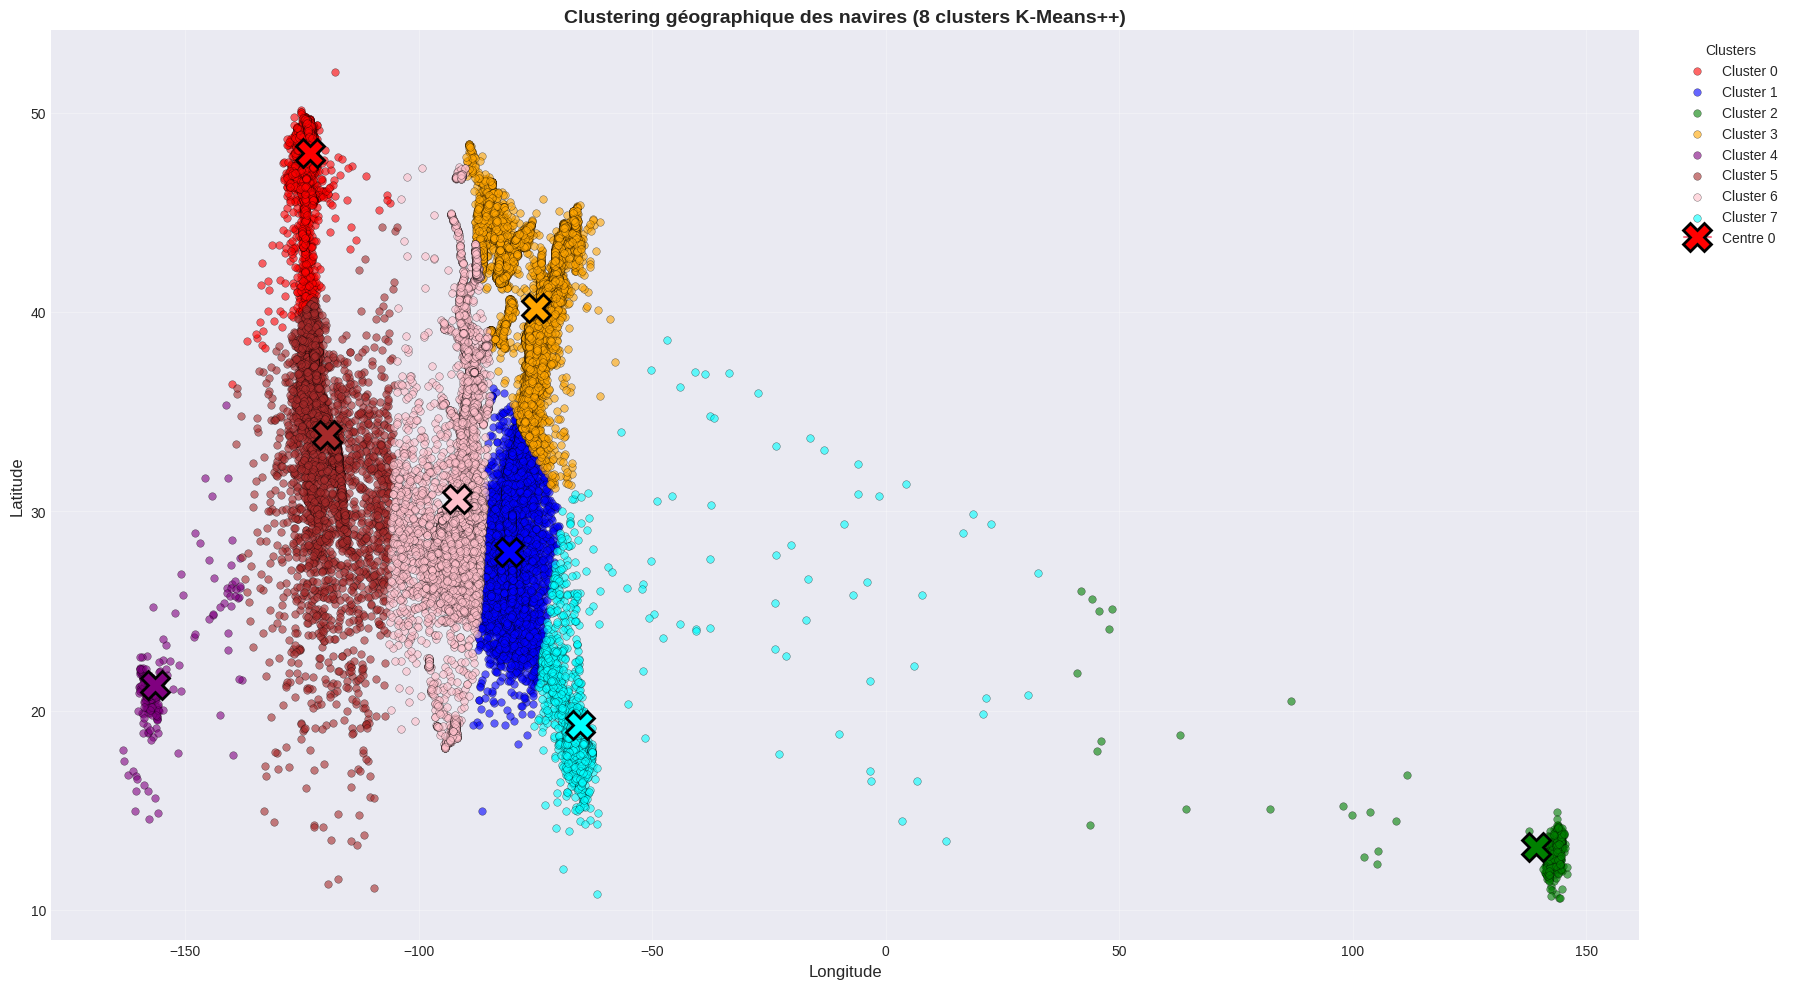


🎯 Clustering géographique avec 8 zones distinctes


In [12]:
# Visualisation matplotlib avec 8 clusters géographiques
plt.figure(figsize=(18, 10))

# Couleurs distinctes pour 8 clusters
colors_8 = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'cyan']

# Plot vessels by cluster
for cluster_id in range(n_clusters_geo):
    cluster_data = df[df['cluster_geo'] == cluster_id]
    plt.scatter(
        cluster_data['avg_longitude'], 
        cluster_data['avg_latitude'],
        color=colors_8[cluster_id],
        s=30,
        alpha=0.6,
        label=f'Cluster {cluster_id}',
        edgecolors='black',
        linewidth=0.3
    )

# Plot cluster centers
for idx, center in enumerate(centers_geo):
    plt.plot(
        center[1], center[0],
        marker='X',
        markersize=20,
        markeredgecolor='black',
        markeredgewidth=2,
        markerfacecolor=colors_8[idx],
        label=f'Centre {idx}' if idx == 0 else ''
    )

plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.title(f'Clustering géographique des navires ({n_clusters_geo} clusters K-Means++)', 
         fontsize=14, fontweight='bold')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), title="Clusters")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n🎯 Clustering géographique avec {n_clusters_geo} zones distinctes")

In [13]:
# Carte interactive Folium avec 8 clusters géographiques
import folium

# Calculer le centre
center_lat = df['avg_latitude'].mean()
center_lon = df['avg_longitude'].mean()

# Créer la carte
m_geo = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=5,
    tiles='OpenStreetMap'
)

# Couleurs pour 8 clusters
colors_8_folium = ['red', 'blue', 'green', 'orange', 'purple', 'darkred', 'pink', 'cadetblue']

# Ajouter les navires par cluster
for cluster_id in range(n_clusters_geo):
    cluster_data = df[df['cluster_geo'] == cluster_id]
    color = colors_8_folium[cluster_id]
    
    for idx, row in cluster_data.iterrows():
        folium.CircleMarker(
            location=[row['avg_latitude'], row['avg_longitude']],
            radius=4,
            popup=f"""
                <b>Zone:</b> {cluster_id}<br>
                <b>MMSI:</b> {row['mmsi']}<br>
                <b>Navire:</b> {row['vessel_name']}<br>
                <b>Type:</b> {row['vessel_type']}<br>
                <b>Vitesse:</b> {row['avg_speed']:.1f} kn<br>
                <b>Distance:</b> {row['total_distance_km']:.0f} km
            """,
            color=color,
            fill=True,
            fillColor=color,
            fillOpacity=0.7,
            weight=1
        ).add_to(m_geo)

# Ajouter les centres de clusters
for idx, center in enumerate(centers_geo):
    folium.Marker(
        location=[center[0], center[1]],
        popup=f'<b>Centre Cluster {idx}</b>',
        icon=folium.Icon(color='black', icon='star')
    ).add_to(m_geo)

# Légende
legend_html = f'''
<div style="position: fixed; 
     top: 10px; right: 10px; width: 250px; height: auto; 
     background-color: white; z-index:9999; font-size:13px;
     border:2px solid grey; padding: 10px; border-radius: 5px;">
     <p style="margin:0; font-weight:bold; font-size:15px;">Zones géographiques</p>
     <p style="margin:5px 0; font-size:11px; color:gray;">K-Means++ ({n_clusters_geo} clusters)</p>
     <hr style="margin:8px 0;">
'''
for i in range(n_clusters_geo):
    count = (df['cluster_geo'] == i).sum()
    color = colors_8_folium[i]
    legend_html += f'<p style="margin:3px 0;"><i class="fa fa-circle" style="color:{color}"></i> Zone {i}: {count} navires</p>'
legend_html += '</div>'

m_geo.get_root().html.add_child(folium.Element(legend_html))

# Sauvegarder
map_path_geo = '/home/yani/master1/PROJET/ais/notebooks/clustering_map_geo.html'
m_geo.save(map_path_geo)

print(f"🗺️ Carte géographique avec {n_clusters_geo} zones créée !")
print(f"✅ Sauvegardée: {map_path_geo}")

# Afficher la carte
m_geo

ModuleNotFoundError: No module named 'folium'

## 💾 12. Sauvegarde des résultats dans la base de données

In [ ]:
# Créer une table pour stocker les résultats du clustering
create_table_query = """
CREATE TABLE IF NOT EXISTS vessel_cluster (
    vessel_id INTEGER PRIMARY KEY REFERENCES vessel(id),
    cluster_id INTEGER NOT NULL,
    cluster_method VARCHAR(50) DEFAULT 'kmeans',
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);
"""

try:
    cursor = conn.cursor()
    cursor.execute(create_table_query)
    conn.commit()
    print("✅ Table 'vessel_cluster' créée avec succès")
    
    # Insérer les résultats
    insert_query = """
    INSERT INTO vessel_cluster (vessel_id, cluster_id, cluster_method)
    VALUES (%s, %s, %s)
    ON CONFLICT (vessel_id) 
    DO UPDATE SET cluster_id = EXCLUDED.cluster_id, created_at = CURRENT_TIMESTAMP;
    """
    
    data_to_insert = [
        (int(row['vessel_id']), int(row['cluster_kmeans']), 'kmeans')
        for _, row in df.iterrows()
    ]
    
    cursor.executemany(insert_query, data_to_insert)
    conn.commit()
    print(f"✅ {len(data_to_insert)} résultats de clustering insérés dans la base de données")
    
    cursor.close()
    
except Exception as e:
    print(f"❌ Erreur lors de la sauvegarde: {e}")
    conn.rollback()

## 🔒 14. Fermeture de la connexion

In [ ]:
# Fermer la connexion
if conn:
    conn.close()
    print("✅ Connexion à la base de données fermée")